# Scientific Programming Assignment

### Date: 18.10.2026


## Introduction

This dataset describes 187 children who had hematopoietic stem cell transplantation from an unrelated donor (Kalwak et al., 2010). They presented with different types of malignant hematological diseases (acute lymphoblastic leukemia, acute myelogenous leukemia), as well as non-malignant conditions (Fanconi anemia, severe aplastic anemia) (Kalwak et al., 2010). This study aims to answer the question: "Does an increase in the CD34+ cell dose relative to the recipient's body weight improve the survival in children without an acute or chronic risk of graft-versus-host disease (GvHD)?"

This notebook assumes that the `bone-marrow.arff` file is in the same folder as the notebook.

## Part I. Data loading and exploratory analysis

This section prepares the dataset for the subsequent analyses. The first part imports all the libraries needed to run the entire notebook, then I loaded the '.arff' file and previewed it to determine which cleaning steps are needed. 

### 1. 1. Import libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
import seaborn as sns
import missingno as msno
import statsmodels.formula.api as smf
from lifelines import CoxPHFitter
from lifelines.statistics import logrank_test
from scipy.io import arff
from sklearn.ensemble import IsolationForest
from lifelines import KaplanMeierFitter

### 1. 2. Exploratory analysis
In this section, I first converted the .arff file into a pandas data frame so it could be analyzed. Subsequently, I printed the data shape and the original dataset contains 187 rows and 37 columns.

Furthermore, I checked the distribution of `survival_status` (0 -alive, 1- dead) to see how many patients died after the transplant and how many were alive (at the latest follow-up): 102 were alive and 85 died. These numbers will help later in the exploratory analysis for the Cox Proportional Hazards model.

In [2]:
# Load the dataset and convert to pandas data frame
data, meta = arff.loadarff('bone-marrow.arff')
df = pd.DataFrame(data)

# Print basic information about the data frame
print(df.shape[1])
df.info()
df.head()

37
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Recipientgender       187 non-null    object 
 1   Stemcellsource        187 non-null    object 
 2   Donorage              187 non-null    float64
 3   Donorage35            187 non-null    object 
 4   IIIV                  187 non-null    object 
 5   Gendermatch           187 non-null    object 
 6   DonorABO              187 non-null    object 
 7   RecipientABO          187 non-null    object 
 8   RecipientRh           187 non-null    object 
 9   ABOmatch              187 non-null    object 
 10  CMVstatus             187 non-null    object 
 11  DonorCMV              187 non-null    object 
 12  RecipientCMV          187 non-null    object 
 13  Disease               187 non-null    object 
 14  Riskgroup             187 non-null    object 
 15  Txpostrelapse       

,Recipientgender,Stemcellsource,Donorage,Donorage35,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,ABOmatch,...,extcGvHD,CD34kgx10d6,CD3dCD34,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV,survival_time,survival_status
0,b'1',b'1',22.830137,b'0',b'1',b'0',b'1',b'1',b'1',b'0',...,b'1',7.20,1.338760,5.38,35.0,19.0,51.0,32.0,999.0,0.0
1,b'1',b'0',23.342466,b'0',b'1',b'0',b'-1',b'-1',b'1',b'0',...,b'1',4.50,11.078295,0.41,20.6,16.0,37.0,1000000.0,163.0,1.0
2,b'1',b'0',26.394521,b'0',b'1',b'0',b'-1',b'-1',b'1',b'0',...,b'1',7.94,19.013230,0.42,23.4,23.0,20.0,1000000.0,435.0,1.0
3,b'0',b'0',39.684932,b'1',b'1',b'0',b'1',b'2',b'1',b'1',...,b'?',4.25,29.481647,0.14,50.0,23.0,29.0,19.0,53.0,1.0
4,b'0',b'1',33.358904,b'0',b'0',b'0',b'1',b'2',b'0',b'1',...,b'1',51.85,3.972255,13.05,9.0,14.0,14.0,1000000.0,2043.0,0.0


In [3]:
# Print class distribution 
print(df['survival_status'].value_counts())

survival_status
0.0    102
1.0     85
Name: count, dtype: int64


## Part II. Data preparation

In the next section, I cleaned the data, removed the columns that are not neccesary for my research question, and checked for missing values. Moreover, I examined whether the variables with missing values ​​were correlated with each other, and how complete each column is. 

### 2.1. Data cleaning
Because the categorical values were in the form of bytes objects (b'1'), I converted them into strings and printed the converted values.

Subsequently, I eliminated the irrelevant columns that are not needed to answer my research question: `DonorABO`, `RecipientABO`, `RecipientRh`, `ABOmatch`, `Antigen`, `Alel`, `Txpostrelapse`. The first four variables describe the compatibility between donor and recipient regarding ABO and Rh blood groups. For this survival analysis and research question I chose to focus on `Stemcellsource`, `Recipientage` and `CD34kgx10d6` variables instead. The `Antigen` and `Alel` variables describe the differences between donor and recipient regarding antigens and alleles, and the information is already described in the `HLAmatch` variable. The `Txpostrelapse` variable describes a second transplant following relapse, and including it will not provide important information for the first transplant. After elimination, the dataset consists of 187 rows and 30 columns.

Moreover, I printed the columns that contained '?', which is not recognized as a missing value. I replaced them with NaN values and counted the missing values. Finally, there are 7 columns with missing values: `CMVstatus` (16), `DonorCMV` (2), `RecipientCMV` (14), `extcGvHD` (31), `CD3dCD34` (5), `CD3dkgx10d8` (5), `Rbodymass` (2).

In [4]:
# Convert bytes objects to string 
for col in df.select_dtypes([object]).columns:
    df[col] = df[col].str.decode('utf-8')

# Print the converted values
print(df['Recipientgender'].unique())


['1' '0']


In [5]:
# Drop irrelevant columns from data frame
columns_to_drop = ['DonorABO', 'RecipientABO', 'RecipientRh', 'ABOmatch',
                    'Antigen', 'Alel', 'Txpostrelapse']

df = df.drop(columns=columns_to_drop)

# Print data frame shape after removal
print(df.shape)
print(df.columns.tolist())

(187, 30)
['Recipientgender', 'Stemcellsource', 'Donorage', 'Donorage35', 'IIIV', 'Gendermatch', 'CMVstatus', 'DonorCMV', 'RecipientCMV', 'Disease', 'Riskgroup', 'Diseasegroup', 'HLAmatch', 'HLAmismatch', 'HLAgrI', 'Recipientage', 'Recipientage10', 'Recipientageint', 'Relapse', 'aGvHDIIIIV', 'extcGvHD', 'CD34kgx10d6', 'CD3dCD34', 'CD3dkgx10d8', 'Rbodymass', 'ANCrecovery', 'PLTrecovery', 'time_to_aGvHD_III_IV', 'survival_time', 'survival_status']


In [6]:
# Print all columns which contain missing values due to bytes conversion
for col in df.select_dtypes([object]).columns:
    if '?' in df[col].unique():
        print(col, '-', df[col].unique())

# Replace "?" with nan and print the new missing value count
df = df.replace('?', np.nan)
print(df.isnull().sum())

CMVstatus - ['3' '0' '2' '1' '?']
DonorCMV - ['1' '0' '?']
RecipientCMV - ['1' '0' '?']
extcGvHD - ['1' '?' '0']
Recipientgender          0
Stemcellsource           0
Donorage                 0
Donorage35               0
IIIV                     0
Gendermatch              0
CMVstatus               16
DonorCMV                 2
RecipientCMV            14
Disease                  0
Riskgroup                0
Diseasegroup             0
HLAmatch                 0
HLAmismatch              0
HLAgrI                   0
Recipientage             0
Recipientage10           0
Recipientageint          0
Relapse                  0
aGvHDIIIIV               0
extcGvHD                31
CD34kgx10d6              0
CD3dCD34                 5
CD3dkgx10d8              5
Rbodymass                2
ANCrecovery              0
PLTrecovery              0
time_to_aGvHD_III_IV     0
survival_time            0
survival_status          0
dtype: int64


In [7]:
# Print the columns with missing values
missing = df.isnull().sum()
print(missing[missing > 0])
print("Columns with missing values:", (missing > 0).sum())

# Print the percentage of missing values for each column
print((df.isnull().mean() * 100).round(1)[missing > 0])

CMVstatus       16
DonorCMV         2
RecipientCMV    14
extcGvHD        31
CD3dCD34         5
CD3dkgx10d8      5
Rbodymass        2
dtype: int64
Columns with missing values: 7
CMVstatus        8.6
DonorCMV         1.1
RecipientCMV     7.5
extcGvHD        16.6
CD3dCD34         2.7
CD3dkgx10d8      2.7
Rbodymass        1.1
dtype: float64


### 2.2. Data visualization of the missing values

After checking which columns have missing values, I made a correlation heatmap to see whether the missing values occur together or independently. From the plot, `RecipientCMV` and `CMVstatus` have a correlation of 0.9, which means that their missingness is strongly linked. This is expected because the `CMVstatus` is the compatibility of the donor and the recipient based on the presence of cytomegalovirus infection, which is what `RecipientCMV` stands for (presence of the cytomegalovirus infection in the recipient). A lot of the missing values are coming from the `RecipientCMV`. The same pattern can be seen between the variables `CD3dCD34` and `CD3dkgx10d8`, which have a correlation of 1.

Furthermore, I made a bar plot for missing values to show how complete each column is. The main variables that will be used for further analysis are `survival_status`, `survival_time`, `CD34kgx10d6`, `Donorage`, `aGvHDIIIIV`, `Diseasegroup`, `Stemcellsource`, `HLAmatch` and `Recipientage`, which have no missing values. The only columns that have missing values are also used in the main models are `CMVstatus` and `extcGvHD`. For the upcoming analyses, no imputation is applied and the patients with a missing value in a model's variable are left out of that model.

<Figure size 600x400 with 0 Axes>

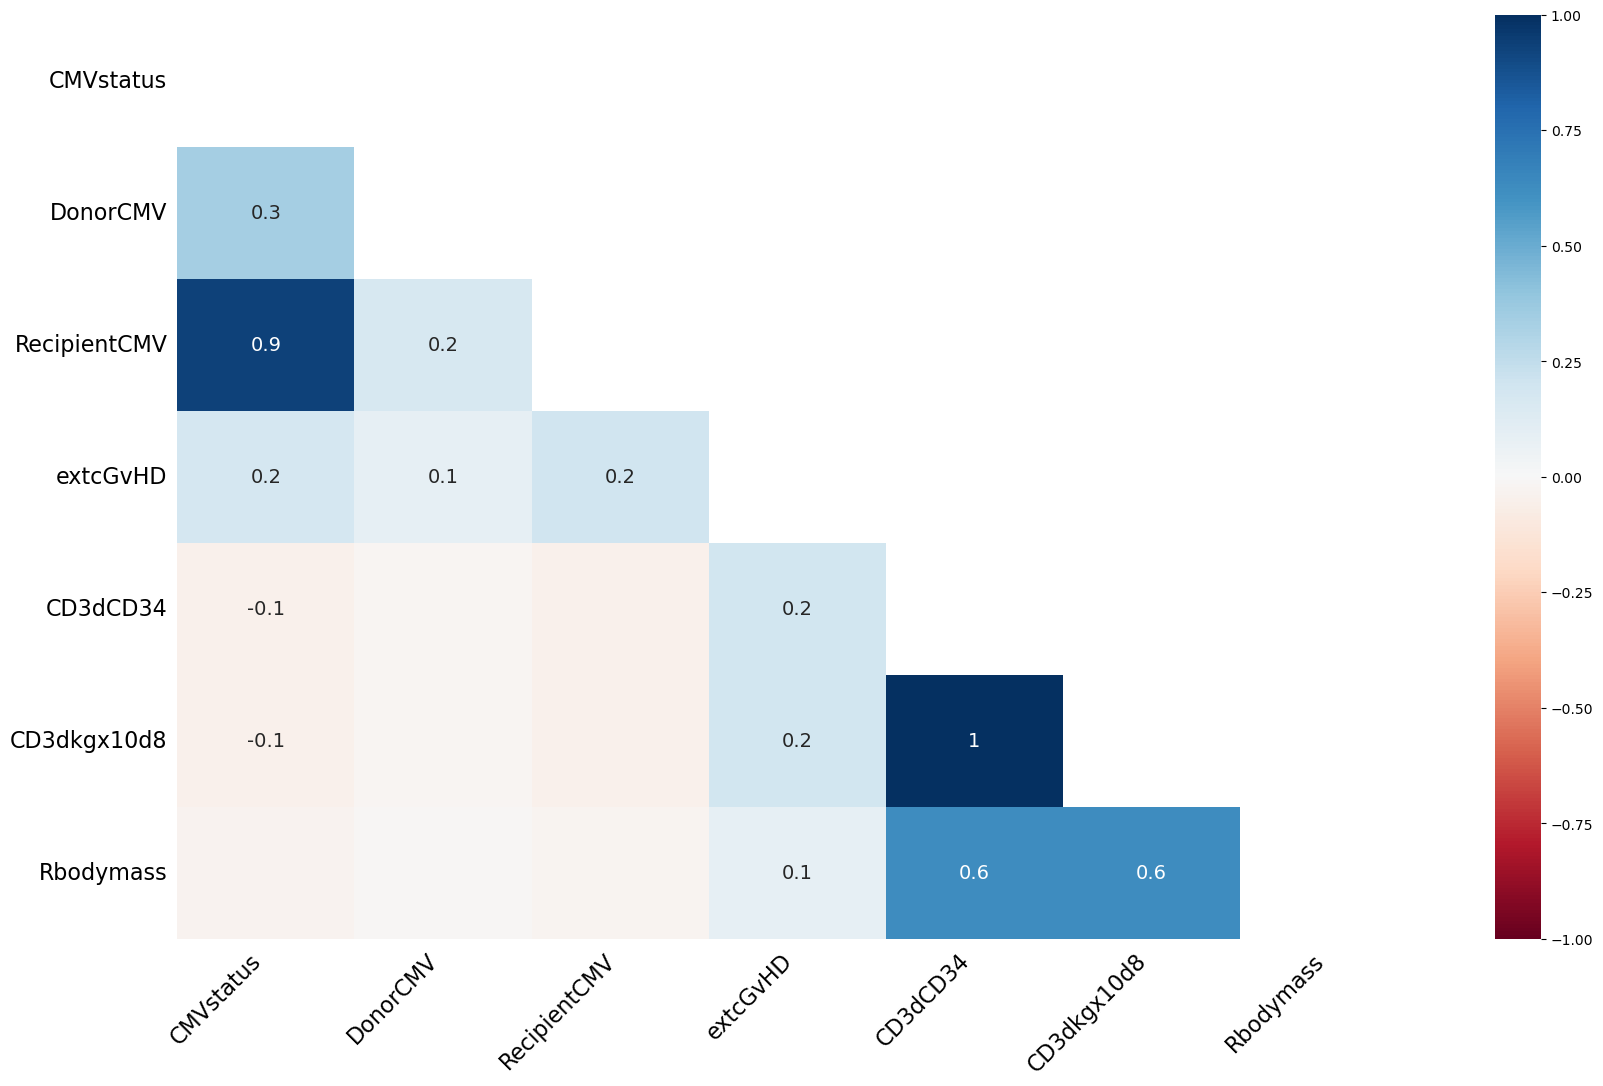

In [8]:
# Plot missing values heatmap for categorical values
plt.figure(figsize=(6, 4))
msno.heatmap(df)
plt.show()

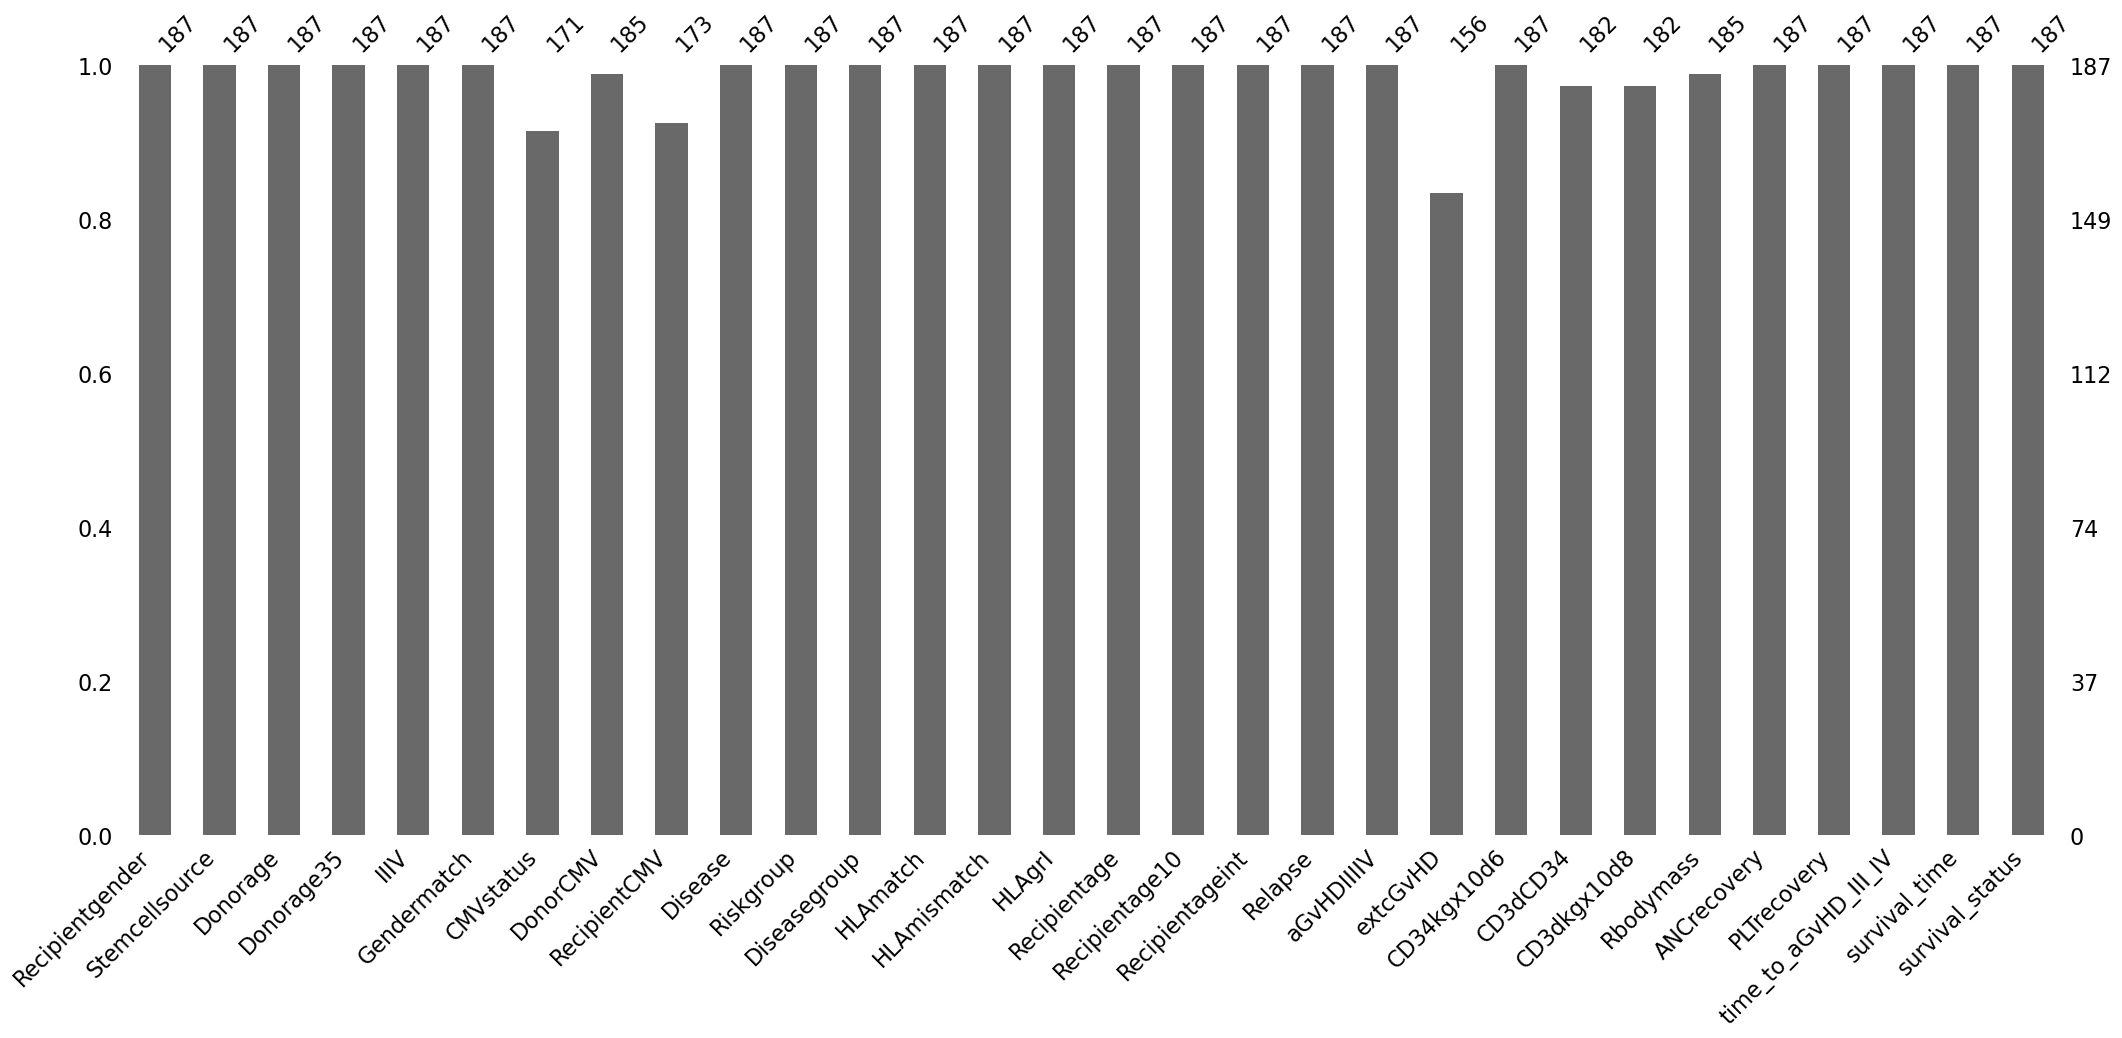

In [9]:
# Plot missing value as bar chart (how complete each column is)
msno.bar(df)
plt.show()

## Part III. Checking the outliers

In this section, I checked outliers for the continuous variables, first with the univariate boxplots and then with Isolation Forest to see whether the patients are unusual in combination. I decided to not remove the outliers, as the sensitivity analysis (Part V) did not reveal extreme results.

### 3. 1. Univariate boxplots 

I checked for outliers using boxplots on four continuous variables that are needed for the analysis: `CD34kgx10d6`, `Recipientage`, `Donorage`, and `survival_time`. From the boxplots, only CD34+ dose variable showed outliers. I chose not to remove them, because I also ran a sensitivity analysis without outliers for both of the survival analysis methods (Part V). The results showed that for the Cox Hazard Proportional method, the p-value = 0.01 and the hazard ratio (HR) = 0.96 without outliers and a p-value = 0.03 and HR = 0.97 with outliers. For the Kaplan-Meier method, the log-rank test showed a p-value = 0.01 without outliers and a p-value = 0.012 with outliers. In both of the analyses, the outliers did not change the results drastically, so I kept all the samples




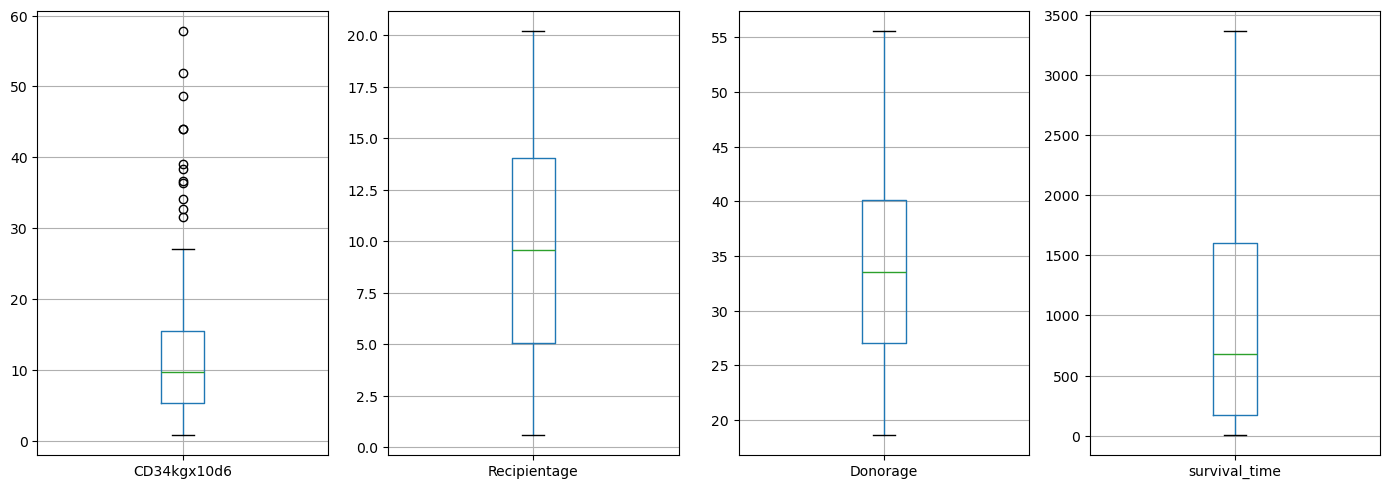

In [10]:
# Plot the columns with missing values as univariate boxplots to find outliers 
fig, axes = plt.subplots(1, 4, figsize=(14, 5))

df.boxplot(column='CD34kgx10d6', ax=axes[0])
df.boxplot(column='Recipientage', ax=axes[1])
df.boxplot(column='Donorage', ax=axes[2])
df.boxplot(column='survival_time', ax=axes[3])

plt.tight_layout()
plt.show()

 ### 3.2. Multivariate outliers (Isolation Forest)

I ran an Isolation Forest to see the multivariate outliers on the same four variables (`CD34kgx10d6`, `Recipientage`, `Donorage`, and `survival_time`) because the boxplots only show one variable separately and I wanted to see if they are unusual in combination. I checked four contamination rates of 5%, 10%, 15% and 20%.

Therefore, I set the contamination rate at 5% to only highlight the patients that are extreme. There were 10 outliers, highlighted in blue in the plot and they are grouped mainly within the `CD34kgx10d6` variable.

contamination=0.05: 10 outliers (5.3%)
contamination=0.1: 19 outliers (10.2%)
contamination=0.15: 28 outliers (15.0%)
contamination=0.2: 38 outliers (20.3%)
Result
 1    177
-1     10
Name: count, dtype: int64


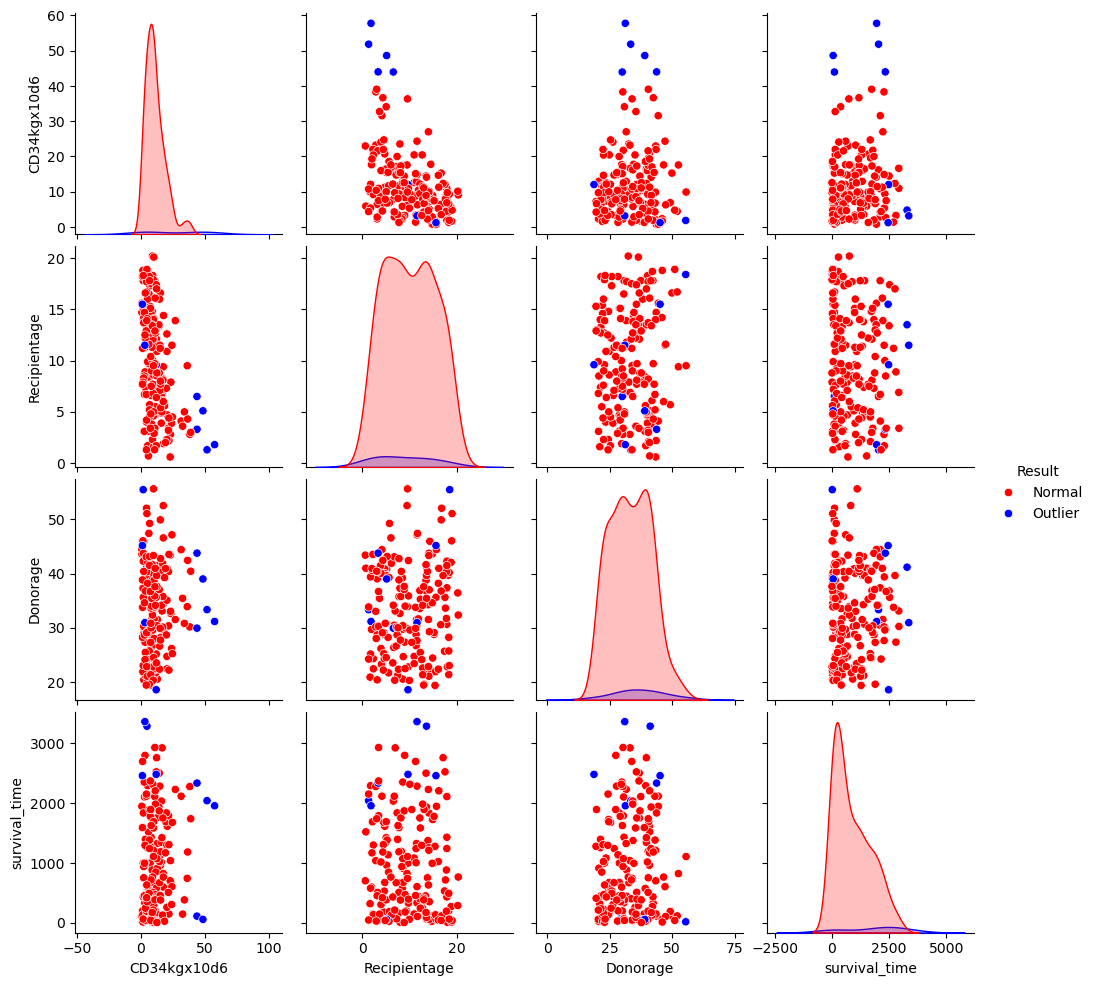

In [11]:
# Check how the number of outliers changes with different contamination rates
features = df[['CD34kgx10d6', 'Recipientage', 'Donorage', 'survival_time']].dropna()
for c in [0.05, 0.1, 0.15, 0.2]:
    isolation_test = IsolationForest(contamination=c, random_state=42)
    labels = isolation_test.fit_predict(features.drop(columns=['Result'], errors='ignore'))
    number_outliers = (labels == -1).sum()
    print(f'contamination={c}: {number_outliers} outliers ({number_outliers/len(features)*100:.1f}%)')

# Apply the isolation forest algorithm on the mentioned variables
isolation_forest = IsolationForest(contamination=0.05, random_state=42)
outlier_labels = isolation_forest.fit_predict(features)

# Print the number of results for each class
features['Result'] = outlier_labels 
print(features['Result'].value_counts())

# Plot the results along with the sns pairplot
features_plot = features.copy()
features_plot['Result'] = features_plot['Result'].map({1: 'Normal', -1: 'Outlier'})

sns.pairplot(features_plot, hue='Result', palette={'Normal': 'red', 'Outlier': 'blue'})
plt.show()

## Part IV: Preparing the data for the survival analysis methods

In this section, I performed the final data checks before running the survival analysis methods.

### 4.1. Multicollinearity 

Before building the models, I checked if there are any correlations between the numerical variables: `CD34kgx10d6`, `CD3dCD34`, `CD3dkgx10d8`, `Recipientage`, `Donorage`, `Rbodymass`. If two variables are almost the same statistically, including both in the same model would make the results unstable. From the heatmap, `Recipientage` and `Rbodymass` had a correlation of 0.9, meaning that they are highly correlated, and consequently will not be included together in the same model.

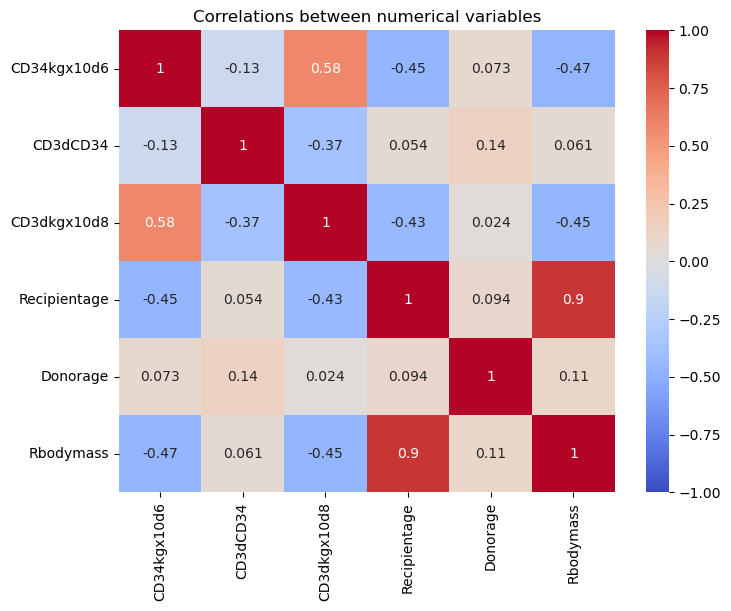

In [12]:
# Plot heatmap of correlations between numerical columns
numeric_columns = ['CD34kgx10d6', 'CD3dCD34', 'CD3dkgx10d8', 'Recipientage', 'Donorage', 'Rbodymass']

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_columns].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlations between numerical variables')
plt.show()

### 4.2. Column conversion to float values

I converted the string columns and categorical columns, because they were stored as text, into float values to be able to run survival analysis and logistic regression models.


In [13]:
# Convert string columns to float for the following calculations
binary_columns = ['Recipientgender', 'Stemcellsource', 'Donorage35', 'Gendermatch',
               'Riskgroup', 'Diseasegroup', 'HLAmismatch', 'Recipientage10',
               'Relapse', 'aGvHDIIIIV', 'RecipientCMV', 'DonorCMV', 'extcGvHD']

for col in binary_columns:
    df[col] = df[col].astype(float)  

# Convert categorical columns to float for the following calculations
multi_categorical_columns = ['CMVstatus', 'HLAmatch', 'HLAgrI', 'Recipientageint']

for col in multi_categorical_columns:
    df[col] = df[col].astype(float)

# Print the resulted conversions   
print(df.dtypes)


Recipientgender         float64
Stemcellsource          float64
Donorage                float64
Donorage35              float64
IIIV                     object
Gendermatch             float64
CMVstatus               float64
DonorCMV                float64
RecipientCMV            float64
Disease                  object
Riskgroup               float64
Diseasegroup            float64
HLAmatch                float64
HLAmismatch             float64
HLAgrI                  float64
Recipientage            float64
Recipientage10          float64
Recipientageint         float64
Relapse                 float64
aGvHDIIIIV              float64
extcGvHD                float64
CD34kgx10d6             float64
CD3dCD34                float64
CD3dkgx10d8             float64
Rbodymass               float64
ANCrecovery             float64
PLTrecovery             float64
time_to_aGvHD_III_IV    float64
survival_time           float64
survival_status         float64
dtype: object


### 4.3.  Descriptive statistics

I printed the descriptive statistics for the variables `CD34kgx10d6`, `survival_time`, `survival_status`, `extcGvHD` and `aGvHDIIIIV`, to check the values that are needed for the subsequent analyses.

In [14]:
# Print key statistics for the plotted columns
print(df[['CD34kgx10d6', 'survival_time', 'survival_status', 'aGvHDIIIIV', 'extcGvHD']].describe())

       CD34kgx10d6  survival_time  survival_status  aGvHDIIIIV    extcGvHD
count   187.000000     187.000000       187.000000  187.000000  156.000000
mean     11.891781     938.743316         0.454545    0.786096    0.820513
std       9.914386     849.589495         0.499266    0.411161    0.384996
min       0.790000       6.000000         0.000000    0.000000    0.000000
25%       5.350000     168.500000         0.000000    1.000000    1.000000
50%       9.720000     676.000000         0.000000    1.000000    1.000000
75%      15.415000    1604.000000         1.000000    1.000000    1.000000
max      57.780000    3364.000000         1.000000    1.000000    1.000000


## Part V: Survival analysis methods

In this section, the survival analysis methods Kaplan-Meier and the Cox Proportional Hazards Model will be applied and the results for each analysis will be discussed and interpreted.

### 5.1. Kaplan-Meier Estimator

Kaplan-Meier Estimator is one of the most widely used method for survival analysis, which analyzes the time until an event will take place. This method is selected for the current analysis to determine survival probability over the time in relation to the CD34+ dose after the stem cell transplant. First, I tested which CD34+ dose (low vs. high) was associated with survival probability. I then tested whether other variables might influence survival probability, namely the stem cell source (bone marrow vs. peripheral blood source) and disease type (malignant vs. non-malignant). Finally, I applied the log-rank test to verify the statistical significance of the differences between the Kaplan-Meier curves.

### A. High and low dose of CD34+ cells

I first tested the low dose vs the high dose of CD34+ cells. To obtain comparable groups, I applied the median (9.72) to split the samples. As shown in the figure, the higher dose group curve is above the lower dose group curve. This suggests that a higher dose of CD34+ cells is associated with a higher probability of survival after transplantation. The log-rank test showed a p-value of 0.012, indicating that the difference between the curves is statistically significant.

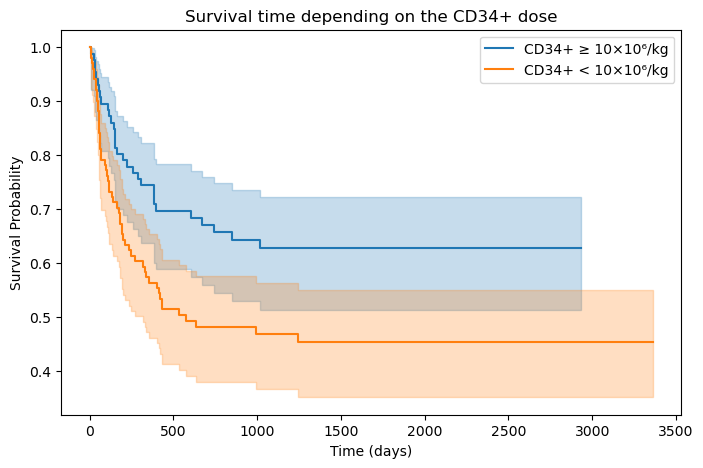

Log-rank test result:  0.01272799698495833


In [15]:
# Split samples by CD34+ dosage (rounded up median; median is 9,72) 
high_dose = df['CD34kgx10d6'] >= 10
low_dose = df['CD34kgx10d6'] < 10

# Create a KaplanMeierFitter object for both categories
kmf_high_dose = KaplanMeierFitter()
kmf_low_dose = KaplanMeierFitter()

plt.figure(figsize=(8, 5))

# Fit based on survival time, survival status and high dose 
# and plot the survival function
kmf_high_dose.fit(durations=df[high_dose]['survival_time'], 
             event_observed=df[high_dose]['survival_status'], 
             label='CD34+ ≥ 10×10⁶/kg')
kmf_high_dose.plot_survival_function()

# Fit based on survival time, survival status and low dose 
# and plot the survival function
kmf_low_dose.fit(durations=df[low_dose]['survival_time'], 
            event_observed=df[low_dose]['survival_status'], 
            label='CD34+ < 10×10⁶/kg')
kmf_low_dose.plot_survival_function()

# Set the plot`s title, axes and show it 
plt.title('Survival time depending on the CD34+ dose')
plt.xlabel('Time (days)')
plt.ylabel('Survival Probability')
plt.legend()
plt.show()

# Perform the log-rank test between the high and low dose
results = logrank_test(
    durations_A=df[high_dose]['survival_time'], 
    durations_B=df[low_dose]['survival_time'],
    event_observed_A=df[high_dose]['survival_status'], 
    event_observed_B=df[low_dose]['survival_status']
)

print("Log-rank test result: ", results.p_value)

### B. Stem cell source

After observing that the higher dose of CD34+ cells increases the probability of survival after transplantation, I examined whether the probability of survival is conditioned by the source of the stem cells. From the plot, the curve of the cells from peripheral blood source is higher than the curve of cells which are coming from bone marrow. This indicates that, after transplantation, the cells from the peripheral blood source increases the chance of survival. The log-rank test showed a p-value of 0.05, indicating that the difference between the curves is statistically significant.

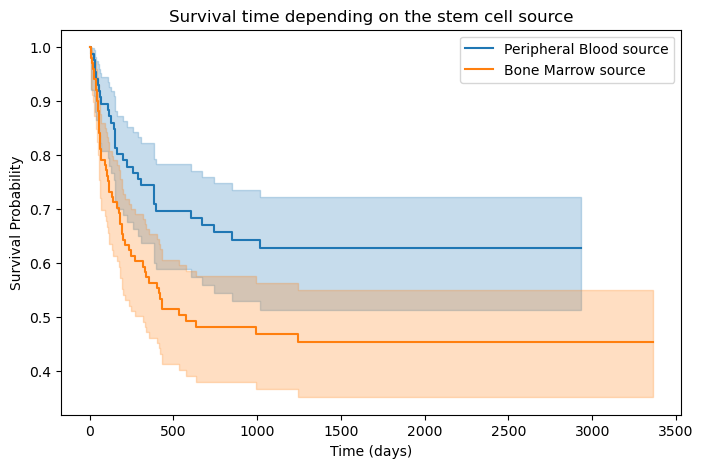

Log-rank test result:  0.05021141405239939


In [16]:
# Split samples by stem cell source into peripheral blood source and bone marrow source
peripheral_blood = df['Stemcellsource'] == 1
bone_marrow = df['Stemcellsource'] == 0

# Create a KaplanMeierFitter object for both categories
kmf_peripheral_blood = KaplanMeierFitter()
kmf_bone_marrow = KaplanMeierFitter()

plt.figure(figsize=(8, 5))

# Fit based on survival time, survival status and peripheral blood source 
# and plot the survival function
kmf_peripheral_blood.fit(durations=df[high_dose]['survival_time'], 
             event_observed=df[high_dose]['survival_status'], 
             label='Peripheral Blood source')
kmf_peripheral_blood.plot_survival_function()

# Fit based on survival time, survival status and bone marrow source
# and plot the survival function
kmf_bone_marrow.fit(durations=df[low_dose]['survival_time'], 
            event_observed=df[low_dose]['survival_status'], 
            label='Bone Marrow source')
kmf_bone_marrow.plot_survival_function()

# Set the plot`s title, axes and show it 
plt.title('Survival time depending on the stem cell source')
plt.xlabel('Time (days)')
plt.ylabel('Survival Probability')
plt.legend()
plt.show()

# Perform the log-rank test between the peripehral blood and bone marrow sources
results = logrank_test(
    durations_A=df[peripheral_blood]['survival_time'], 
    durations_B=df[bone_marrow]['survival_time'],
    event_observed_A=df[peripheral_blood]['survival_status'], 
    event_observed_B=df[bone_marrow]['survival_status']
)

print("Log-rank test result: ", results.p_value)

### C. Disease type (malignant vs nonmalignant)

Lastly, I wanted to examine whether the type of disease (malignant vs nonmalignant) could influence the probability of survival after the transplant. As shown in the figure, both curves almost overlap, and this observation is supported by the log-rank test with a p-value of 0.4. Therefore, there was not any statistically significant difference found in survival between the two types of diease.

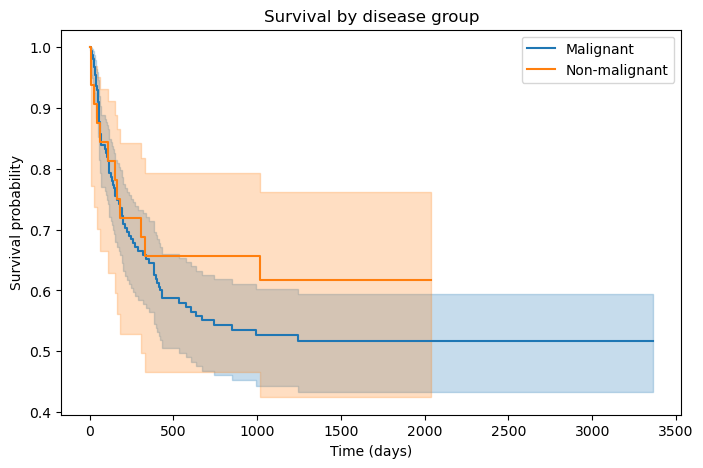

Log-rank test result:  0.4016964368616628


In [17]:
# Split samples by disease status into malignant and non-malignant
malignant = df['Diseasegroup'] == 1
nonmalignant = df['Diseasegroup'] == 0

# Create a KaplanMeierFitter object for both categories
kmf_malignant = KaplanMeierFitter()
kmf_nonmalignant = KaplanMeierFitter()

plt.figure(figsize=(8, 5))

# Fit based on survival time, survival status and type of disease (malignant)
# and plot the survival function 
kmf_malignant.fit(durations=df[malignant]['survival_time'], 
              event_observed=df[malignant]['survival_status'], 
              label='Malignant')
kmf_malignant.plot_survival_function()

# Fit based on survival time, survival status and type of disease (nonmalignant)
# and plot the survival function
kmf_nonmalignant.fit(durations=df[nonmalignant]['survival_time'], 
                  event_observed=df[nonmalignant]['survival_status'], 
                  label='Non-malignant')
kmf_nonmalignant.plot_survival_function()

plt.title('Survival by disease group')
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')
plt.legend()
plt.show()

# Perform the log-rank test between the malignant and nonmalignant disease group
results = logrank_test(
    durations_A=df[malignant]['survival_time'], 
    durations_B=df[nonmalignant]['survival_time'],
    event_observed_A=df[malignant]['survival_status'], 
    event_observed_B=df[nonmalignant]['survival_status']
)

print("Log-rank test result: ", results.p_value)

### 5.2. Cox Proportional Hazards Model

The next method used in this project is the Cox Proportional Hazards Model. This method was chosen because, unlike Kaplan-Meier, it can assess the effect of different variables on the duration of time until an event will happen. For this analysis, I wanted to assess which variables are associated with survival after transplantation.

### A. Simple model based on CD34+ cells

I first tested on the dose of CD34+ cells as the only covariate, to keep the model as simple as possible. From the results it can be seen that the hazard ratio (HR) is 0.97, which means that the dose of CD34+ cells slightly decreases the risk of death after transplantation. This observation is also statistically significant because the p-value = 0.03.

In [18]:
# Create a CoxPHFitter object
cph = CoxPHFitter()
# Fit the Cox Proportional Hazards model based on dosage
cph.fit(df[['survival_time', 'survival_status', 'CD34kgx10d6']], 
        duration_col='survival_time', 
        event_col='survival_status')

cph.print_summary()

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 187
number of events observed = 85
   partial log-likelihood = -417.12
         time fit was run = 2026-10-18 16:15:20 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
CD34kgx10d6 -0.03      0.97      0.01           -0.06           -0.00                0.95                1.00

             cmp to     z    p  -log2(p)
covariate                               
CD34kgx10d6    0.00 -2.11 0.03      4.85
---
Concordance = 0.60
Partial AIC = 836.24
log-likelihood ratio test = 5.26 on 1 df
-log2(p) of ll-ratio test = 5.52

### B. Checking the Cox Proportional Hazards model and Kaplan-Meier Estimator without outliers

After running the simple Cox Proportional Hazards model and the Kaplan-Meier analysis on the CD34+ dose, I perfomed a sensitivity analysis to check if the results were influenced by the outliers identified during the pre-processing part of the project. For the Cox Proportional Hazards model, the results (HR = 0.96 and p-value = 0.01)  were similar to those obtained from the analysis with outliers (HR = 0.97 and p-value = 0.03). For the Kaplan-Meier estimator, the higher dose group curve of CD34+ was above the curve for the lower dose group (p-value = 0.01), a result consistent with the analysis with outliers (p-value = 0.012). Although the results are slightly better for the analysis without outliers, the differences were small and the conclusions did not change. Therefore, I chose not to remove them from the analysis.

<lifelines.CoxPHFitter: fitted with 177 total observations, 95 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 177
number of events observed = 82
   partial log-likelihood = -395.90
         time fit was run = 2026-10-18 16:15:24 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
CD34kgx10d6 -0.04      0.96      0.02           -0.08           -0.01                0.93                0.99

             cmp to     z    p  -log2(p)
covariate                               
CD34kgx10d6    0.00 -2.57 0.01      6.60
---
Concordance = 0.60
Partial AIC = 793.81
log-likelihood ratio test = 7.56 on 1 df
-log2(p) of ll-ratio test = 7.39

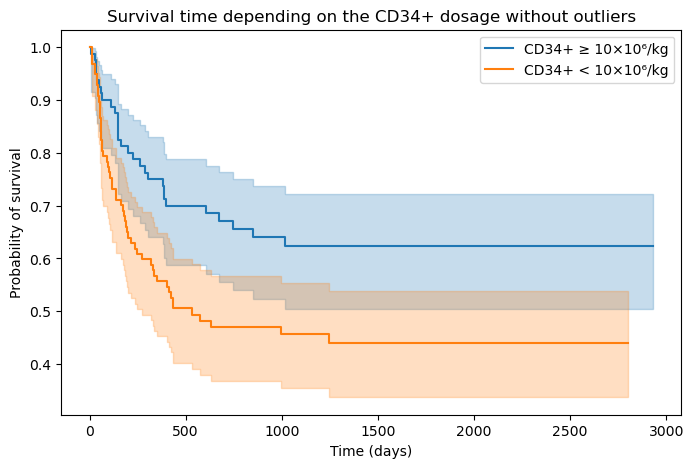

0.010544096904916919


In [19]:
# Get the outliers indexes and create a copy of the data frame without them
outlier_indexes = features[features['Result'] == -1].index
df_no_outliers = df.drop(index=outlier_indexes)

# Create a simple Cox Proportional Hazards model like before
cph_no_outliers = CoxPHFitter()
cph_no_outliers.fit(df_no_outliers[['survival_time', 'survival_status', 'CD34kgx10d6']].dropna(),
               duration_col='survival_time', event_col='survival_status')
cph_no_outliers.print_summary()

# Split the dataframe based on CD34+ dosage like before
high = df_no_outliers['CD34kgx10d6'] >= 10
low = df_no_outliers['CD34kgx10d6'] < 10

# Create the KaplanMeierFitter object for both the high and low dose of CD34+ cell
kmf_high_dosage = KaplanMeierFitter()
kmf_low_dosage = KaplanMeierFitter()

plt.figure(figsize=(8, 5))

# Fit based on survival time, survival status and dosage of the CD34+ cells
# and plot the survival function
kmf_high_dosage.fit(df_no_outliers[high]['survival_time'], df_no_outliers[high]['survival_status'],
          label='CD34+ ≥ 10×10⁶/kg')
kmf_high_dosage.plot_survival_function()

kmf_low_dosage.fit(df_no_outliers[low]['survival_time'], df_no_outliers[low]['survival_status'],
          label='CD34+ < 10×10⁶/kg')
kmf_low_dosage.plot_survival_function()

# Plot the Kaplan-Meier Estimator curves for both high and low dosage
plt.title('Survival time depending on the CD34+ dosage without outliers')
plt.xlabel('Time (days)')
plt.ylabel('Probability of survival')
plt.legend()
plt.show()

# Perform log-rank test between high and low dosage groups
res = logrank_test(df_no_outliers[high]['survival_time'], df_no_outliers[low]['survival_time'],
                   df_no_outliers[high]['survival_status'], df_no_outliers[low]['survival_status'])
print(res.p_value)

### C. Analysis based on an extended model

After running the simple model, I tested whether other variables, alongside the CD34+ cells dose, might influence survival after the transplant. Although many variables can affect the probability of survival, I chose to include `Recipientage` in the model because I wanted to see how the cell dose is correlated with the age. I also included `HLAmatch`, which represents the HLA antigen compatibility between the donor and the recipient. Finally, I included `Stemcellsource`, based on Kaplan-Meier analysis results, and because stem cell source is an important factor in a transplantation. 

The results showed that `Stemcellsource` and `CD34kgx10d6` had HR = 0.69 and 0.99, respectively. This indicates a decrease of the risk of death, but this is not statistically significant (p = 0.18 and p = 0.68, respectively). On the other hand, the `HLAmatch` was associated with an increased risk of death (HR = 1.13) but was not statistically significant (p = 0.39). The only variable who had a statisticallly significant association was `Recipientage` (p = 0.02), which was associated with a higher risk of death after transplantation (HR = 1.06).

In [20]:
# Create a CoxPHFitter object
cph_extended = CoxPHFitter()
# Fit the Cox Proportional Hazard model based on dosage, recipient age, HLAmatch
# and stemcellsource
cph_extended.fit(
    df[['survival_time', 'survival_status', 'CD34kgx10d6', 
        'Recipientage', 'HLAmatch', 'Stemcellsource']].dropna(), 
    duration_col='survival_time', 
    event_col='survival_status'
)

cph_extended.print_summary()

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 187
number of events observed = 85
   partial log-likelihood = -413.35
         time fit was run = 2026-10-18 16:15:29 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
CD34kgx10d6    -0.01      0.99      0.02           -0.04            0.03                0.96                1.03
Recipientage    0.06      1.06      0.02            0.01            0.11                1.01                1.11
HLAmatch        0.12      1.13      0.14           -0.16            0.40                0.86                1.49
Stemcellsource -0.37      0.69      0.28           -0.92            0.17                0.40                1.19

                cmp to     z    p  -log2(p)
covariate                                  
CD34kgx10d6       0.00 -0.41 0.68      0.55
Recipientage      0.00  2.38 0.02      5.85
HLAmatch          0.00  0.86 0.39      1.36
Stemcellsource    0.00 -1.34 0.18      2.48
---
Concordance = 0.61
Partial AIC = 834.71
log-likelihood ratio test = 12.80 on 4 df
-log2(p) of ll-ratio test = 6.34

### D. Model based on the younger group

Because `Recipientage` showed a statistical significance in survival analysis, I examined whether there is any association between CD34+ dosage and the recipient age split into groups. I plotted a histogram in order to choose how to split the age groups effectively. Based on the histogram results, I chose to split `Recipientage` into two groups: 0–10 years and 10–20 years.

In the Cox Proportional Hazards model for the younger group, the CD34+ dosage had a very slightly reduced risk of death after the transplant (HR = 0.99), but the value was not statistically significant (p = 0.35).

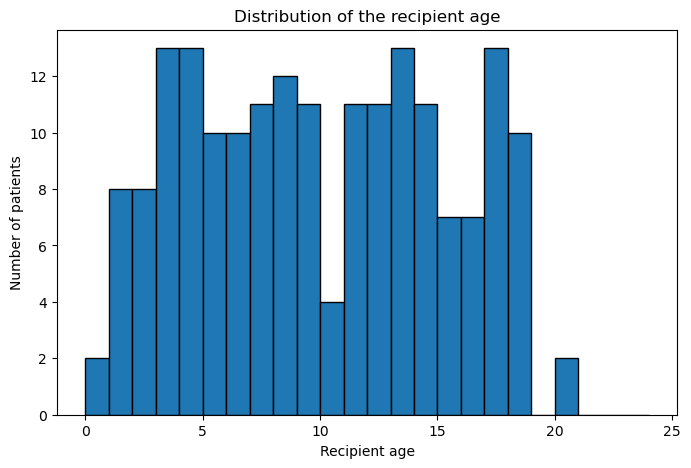

In [21]:
# Plot the figure to represent the distribution of the recipient age 
plt.figure(figsize=(8, 5))
plt.hist(df['Recipientage'], bins=range(0, 25), edgecolor='black') 
plt.xlabel('Recipient age')
plt.ylabel('Number of patients')
plt.title('Distribution of the recipient age')
plt.show()

In [22]:
# Split the samples based on age
young = df[df['Recipientage'] < 10]
# Create a CoxPHFitter object
cph_young_age = CoxPHFitter()
# Fit the Cox Proportional Hazard model based on dosage for the younger group
cph_young_age.fit(young[['survival_time', 'survival_status', 'CD34kgx10d6']],
              duration_col='survival_time', event_col='survival_status')
              
cph_young_age.print_summary()

<lifelines.CoxPHFitter: fitted with 98 total observations, 60 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 98
number of events observed = 38
   partial log-likelihood = -164.36
         time fit was run = 2026-10-18 16:15:36 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
CD34kgx10d6 -0.01      0.99      0.02           -0.05            0.02                0.96                1.02

             cmp to     z    p  -log2(p)
covariate                               
CD34kgx10d6    0.00 -0.93 0.35      1.51
---
Concordance = 0.57
Partial AIC = 330.71
log-likelihood ratio test = 0.95 on 1 df
-log2(p) of ll-ratio test = 1.60

### E. Model based on the older group

In the older group, the dosage of the CD34+ was associated with a slightly lower risk of death (HR = 0.95) after the transplantation, but the value was not statistically significant (p=0.11). Although the HR value was slightly lower than the one from the younger group, both of the associations were not significant. The analysis could not provide evidence that the effect of CD34+ dosage is different based on the recipient age.

In [23]:
# Split the samples based on age
old = df[df['Recipientage'] >= 10]

# Create a CoxPHFitter object
cph_old_age = CoxPHFitter()

# Fit the Cox Proportional Hazards model based on dosage for the older group
cph_old_age.fit(old[['survival_time', 'survival_status', 'CD34kgx10d6']],
            duration_col='survival_time', event_col='survival_status')

cph_old_age.print_summary()

<lifelines.CoxPHFitter: fitted with 89 total observations, 42 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 89
number of events observed = 47
   partial log-likelihood = -193.63
         time fit was run = 2026-10-18 16:15:39 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
CD34kgx10d6 -0.05      0.95      0.03           -0.11            0.01                0.89                1.01

             cmp to     z    p  -log2(p)
covariate                               
CD34kgx10d6    0.00 -1.61 0.11      3.22
---
Concordance = 0.59
Partial AIC = 389.26
log-likelihood ratio test = 2.83 on 1 df
-log2(p) of ll-ratio test = 3.43

### F. Cox Proportional Hazards model including CMVstatus column

Since the `CMVstatus` column has a high number of missing values ​​(16), I chose to include it in the extended Cox Proportional Hazards model to assess the impact of the missing values. When I eliminated them, `CMVstatus` had a HR = 1.05, indicating a small increase in risk of death, but the association was not statistically significant (p = 0.67). 

In [24]:
# Create a CoxPHFitter object
cph_extended = CoxPHFitter()
# Fit the Cox Proportional Hazard model based on dosage, recipient age, HLAmatch
# stemcellsource and CMV status
cph_extended.fit(
    df[['survival_time', 'survival_status', 'CD34kgx10d6', 
        'Recipientage', 'HLAmatch', 'Stemcellsource', 'CMVstatus']].dropna(), 
    duration_col='survival_time', 
    event_col='survival_status'
)

cph_extended.print_summary()

<lifelines.CoxPHFitter: fitted with 171 total observations, 96 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 171
number of events observed = 75
   partial log-likelihood = -358.86
         time fit was run = 2026-10-18 16:15:42 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
CD34kgx10d6    -0.02      0.98      0.02           -0.06            0.02                0.94                1.02
Recipientage    0.05      1.05      0.03           -0.01            0.10                0.99                1.10
HLAmatch        0.12      1.12      0.15           -0.17            0.41                0.84                1.51
Stemcellsource -0.31      0.74      0.30           -0.90            0.29                0.41                1.33
CMVstatus       0.04      1.05      0.11           -0.16            0.25                0.85                1.29

                cmp to     z    p  -log2(p)
covariate                                  
CD34kgx10d6       0.00 -1.08 0.28      1.84
Recipientage      0.00  1.74 0.08      3.62
HLAmatch          0.00  0.79 0.43      1.22
Stemcellsource    0.00 -1.01 0.31      1.68
CMVstatus         0.00  0.42 0.67      0.57
---
Concordance = 0.62
Partial AIC = 727.71
log-likelihood ratio test = 11.71 on 5 df
-log2(p) of ll-ratio test = 4.68

### Part VI. Logistic regression of GvHD to determine the association with CD34+ dose

To answer the last part of the research question, I used logistic regression to determine if an increase in CD34+ dosage will have a higher risk of developing acute or chronic GvHD. The `extcGvHD` had the highest number of the missing values (31) and they were not taken into account, therefore the analysis for chronic GvHD was ran on 156 patients. Because the variables `aGvHDIIIIV` and `extcGvHD` were presented as Yes-0 and No-1, I reversed the order so that I can interpret the results. Therefore, the results showed that an increase in dosage was not significantly associated with a risk for developing acute (coef = 0.0028 and p-value = 0.875) or chronic (coef = -0.0129 and p-value = 0.570) GvHD.


In [25]:
# Reverse the values in the relevant columns 
df['aGvHD_event'] = 1 - df['aGvHDIIIIV']
df['extcGvHD_event'] = 1 - df['extcGvHD']

# Train logistic regression model on acute GvHD values and print the results
model_acute_GvHD = smf.logit('aGvHD_event ~ CD34kgx10d6', data=df).fit()
print("Acute GvHD")
print(model_acute_GvHD.summary())

# Train logistic regression model on extGvHD values and print the results
model_chronic_GvHD = smf.logit('extcGvHD_event ~ CD34kgx10d6', data=df).fit()
print("Chronic GvHD")
print(model_chronic_GvHD.summary())

Optimization terminated successfully.
         Current function value: 0.519018
         Iterations 5
Acute GvHD
                           Logit Regression Results                           
Dep. Variable:            aGvHD_event   No. Observations:                  187
Model:                          Logit   Df Residuals:                      185
Method:                           MLE   Df Model:                            1
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:               0.0001255
Time:                        18:15:45   Log-Likelihood:                -97.056
converged:                       True   LL-Null:                       -97.069
Covariance Type:            nonrobust   LLR p-value:                    0.8760
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -1.3349      0.279     -4.792      0.000      -1.881      -0.789
CD34kgx10d6    

## Part VII. Disscussion

After running these analyses, several conclusions can be drawn. Both the Kaplan-Meier estimator and the Cox Proportional Hazards Model showed relevant results. The Kaplan-Meier Estimator showed a significant survival difference between the high dose and the low dose of CD34+ cells after the transplant (p = 0.012), with the higher dose indicating a higher survival probability. This method also highlighted that the stem cell source could influence survival probability, with peripheral blood source showing higher survival rates. The only variable for which no significant statistical difference was found is the disease type (p = 0.40), meaning there is no evidence that it could influence the survival after the transplant. Additionally, I tested the same methods, excluding the outliers identified with Isolation Forest, and the results did not change significantly, which is why I did not remove them for the current analysis.

Regarding the Cox Proportional Hazards Model, CD34+ dose was significantly associated with a lower risk of death (HR=0.97 , p =0.03), but this effect was no longer significant in the extended model (p=0.68). In that model, the only covariate that could possibly increase the risk of death was recipient age (HR = 1.06,p = 0.02). Consequently, I investigated whether a younger group or an older group might provide further insights about the probability of survival. However, neither of the results were statistically significant. Finally, addressing the last part of my research question, I used logistic regression to investigate whether a higher dose of CD34+ was associated with acute or chronic GvHD might, but no significant association was found. 

As a conclusion, these were the results achieved given the limited time. However, further analyses are required to determine if the effect of CD34+ dose on survival is correlated with any other variables.


### References

1. Unknown. Bone marrow transplant: children. UCI Machine Learning Repository https://doi.org/10.24432/C5NP6Z (2020)

2. Kałwak, K. et al. Higher CD34+ and CD3+ Cell Doses in the Graft Promote Long-Term Survival, and Have No Impact on the Incidence of Severe Acute or Chronic Graft-versus-Host Disease after In Vivo T Cell-Depleted Unrelated Donor Hematopoietic Stem Cell Transplantation in Children. Biology of Blood and Marrow Transplantation 16, 1388–1401 (2010)

3. Jager, K. J., Van Dijk, P. C., Zoccali, C. & Dekker, F. W. The analysis of survival data: the Kaplan–Meier method. Kidney International 74, 560–565 (2008).

4. Tibshirani, R. What is Cox’s Proportional Hazards Model? Significance 19, 38–39 (2022).


